In [1]:
# Check whether msd is correlated with local dimension. Compare this correlation to randomly generated
# data with matching msd values.import pandas as pd
import scipy.stats
from matplotlib import gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.gridspec as gridspec
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
from collections import Counter
import torch
import os
import sys
from BWM.models.isometric_autoencoder import get_density_proxy
# Add project root to path
sys.path.append(os.path.abspath('../../'))
import torch.optim as optim
from BWM.bwm_functions import *
from BWM.models.isometric_autoencoder import SklearnIsometricAutoencoder

plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

# Set global plotting parameters for font size
tick_fontsize = 6
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': tick_fontsize,
    'ytick.labelsize': tick_fontsize,
    'legend.fontsize': 7,
    'figure.titlesize': 7
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cpu


In [2]:

def iso_ae_preprocessing(pseudo_response_tensor):
    """
    Preprocess neural responses intro response matrix (n x kt) for autoencoder.
    """
    response_tensor = np.mean(pseudo_response_tensor, axis=0)
    # Z-score and reshape
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    response_matrix = response_tensor_norm.reshape(-1, response_tensor_norm.shape[2])
    X_transposed = response_matrix.T
    # Scale each row (neuron) to unit length
    row_norms = np.linalg.norm(X_transposed, axis=1, keepdims=True)
    X_pre_pca = X_transposed / (row_norms + 1e-8)
    return X_pre_pca

def calculate_msd_data(response_tensor):
    """
    Calculate Mean Standardized Derivative using finite differences.
    responses: (conditions, time, neurons)
    """
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    diff_responses = np.diff(response_tensor_norm, axis=1)
    # Absolute standardized derivative (already standardized in the previous cell)
    # Mean over conditions and time and pseudo trials

    msd = np.mean(np.abs(diff_responses), axis=(0,1))
    return msd

In [3]:
CP_responses = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/CP_pseudo_responses.npy')


In [4]:
X_CP = iso_ae_preprocessing(CP_responses)

msd_CP = calculate_msd_data(np.mean(CP_responses, axis=0))

In [6]:
def compute_local_dimension_mps(data, k=20):
    # Ensure data is a torch tensor on MPS
    device = torch.device("mps")
    X = torch.tensor(data, dtype=torch.float32, device=device)

    # 1. Compute all-to-all squared Euclidean distances
    # Formula: ||A-B||^2 = ||A||^2 + ||B||^2 - 2*A*B^T
    r = torch.sum(X * X, dim=1, keepdim=True)
    D2 = r - 2 * torch.mm(X, X.t()) + r.t()

    # Clamp to avoid tiny negative numbers due to floating point precision
    D2 = torch.clamp(D2, min=0.0)

    # 2. Get the distances to the k-nearest neighbors
    # k+1 because the closest point is always the point itself (distance 0)
    val, _ = torch.topk(D2, k + 1, largest=False, sorted=True)

    # Extract neighbor distances (skip the self-distance at index 0)
    # Convert squared distances to actual Euclidean distances
    distances = torch.sqrt(val[:, 1:])

    # 3. Apply MLE Intrinsic Dimension formula
    # Avoid log(0) by ensuring distances are strictly positive
    epsilon = 1e-7
    R_k = distances[:, -1:] # Distance to the k-th neighbor

    # Compute the average log ratio
    log_ratio = torch.log(R_k / (distances[:, :-1] + epsilon))
    sum_log_ratio = torch.sum(log_ratio, dim=1)

    # Local dimension formula: (k - 1) / sum(log(R_k / R_i))
    local_dim = (k - 1) / sum_log_ratio

    # Move results back to CPU numpy array
    return local_dim.cpu().numpy()

In [15]:
local_dim = compute_local_dimension_mps(X_CP, k=500)

<Axes: >

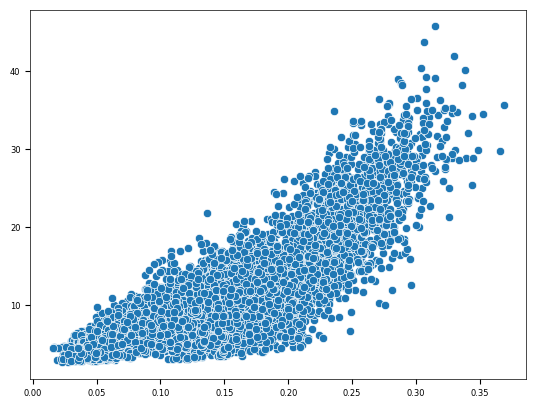

In [16]:
plt.figure()
sns.scatterplot(x = msd_CP, y = local_dim)

In [19]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr, spearmanr

# 1. Setup Device (Apple Silicon GPU Acceleration)
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")
z_neurons_CP = umap.UMAP(densmap = True, dens_lambda=2, n_neighbors=500).fit_transform(X_CP)






Using device: mps


AttributeError: 'numpy.ndarray' object has no attribute 'to'

In [25]:
# --- Dummy Data Setup (Replace with your actual data) ---
n, d = X_CP.shape
# X_2d shape: (n, 2), Y_dd shape: (n, d)
X_2d = torch.FloatTensor(z_neurons_CP)
Y_dd = torch.FloatTensor(X_CP)
L = msd_CP # Your list of length n (e.g., local dimension)
# ---------------------------------------------------------

# 2. Define the MLP Architecture
class ManifoldMapper(nn.Module):
    def __init__(self, input_dim=2, output_dim=200):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, output_dim)
        )

    def forward(self, x):
        return self.net(x)

# 3. Instantiate Model, Loss, and Optimizer
model = ManifoldMapper(input_dim=2, output_dim=d).to(device)
criterion = nn.MSELoss() # Global loss for optimization
optimizer = optim.AdamW(model.parameters(), lr=0.00001)

# Move tensors to the MPS device
X_gpu = X_2d.to(device)
Y_gpu = Y_dd.to(device)

# 4. Training Loop
epochs = 2000
batch_size = 1024

print("Training MLP...")
model.train()
for epoch in range(epochs):
    # Shuffle indices for batching
    permutation = torch.randperm(X_gpu.size(0))

    for i in range(0, X_gpu.size(0), batch_size):
        optimizer.zero_grad()

        indices = permutation[i:i+batch_size]
        batch_x, batch_y = X_gpu[indices], Y_gpu[indices]

        predictions = model(batch_x)
        loss = criterion(predictions, batch_y)

        loss.backward()
        optimizer.step()
    if epoch % 10 == 0:
        print(loss.item())


Training MLP...
0.021811408922076225
0.007649515755474567
0.003836511867120862
0.004064589738845825
0.0043585957027971745
0.0023662184830754995
0.003803770523518324
0.00200079008936882
0.0019464201759546995
0.0034794812090694904
0.0012239430798217654
0.001785301836207509
0.0024720015935599804
0.003674981417134404
0.002769036218523979
0.0025742086581885815
0.002266095019876957
0.0025274460203945637
0.0019699432887136936
0.0021383778657764196
0.002917076926678419
0.001903065131045878
0.0022479461040347815
0.0017550332704558969
0.0021712309680879116
0.002344998763874173
0.0014830079162493348
0.0035595984663814306
0.001345350407063961
0.0021394218783825636
0.0015670493012294173
0.0017119308467954397
0.0007931579602882266
0.001420323853380978
0.0013312709052115679
0.0022318498231470585
0.002837677486240864
0.0014268564991652966
0.0015553474659100175
0.002148133935406804
0.0027635544538497925
0.0020260976161807775
0.0032253607641905546
0.0028485239017754793
0.00287725031375885
0.001865551108

Pearson Correlation: 0.7894
Spearman Correlation: 0.7966


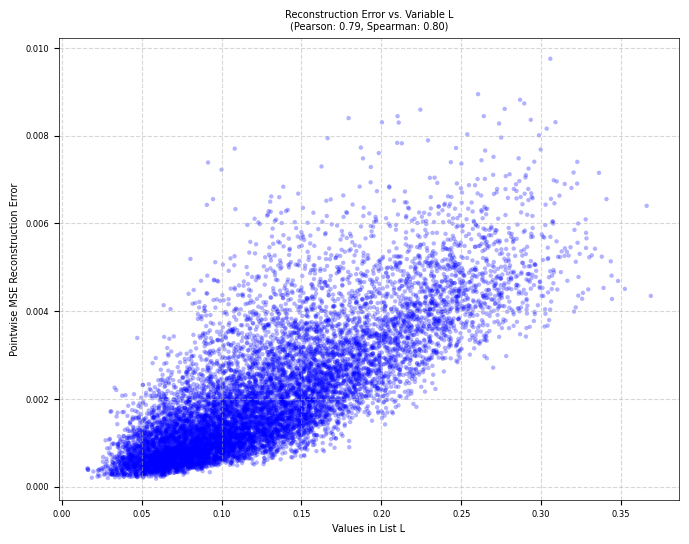

In [26]:
# 5. Compute Pointwise Reconstruction Error
model.eval()
with torch.no_grad():
    # Pass the entire dataset to get predictions
    Y_pred = model(X_gpu)

    # Compute Mean Squared Error *per sample* (mean across the d dimension)
    # Shape changes from (n, d) -> (n,)
    pointwise_error = torch.mean((Y_gpu - Y_pred) ** 2, dim=1)

    # Move back to CPU numpy array for plotting
    errors_np = pointwise_error.cpu().numpy()

# 6. Calculate Statistical Correlation
L_np = np.array(L)
pearson_corr, _ = pearsonr(errors_np, L_np)
spearman_corr, _ = spearmanr(errors_np, L_np)

print(f"Pearson Correlation: {pearson_corr:.4f}")
print(f"Spearman Correlation: {spearman_corr:.4f}")

# 7. Plotting the Relationship
plt.figure(figsize=(8, 6))
# Using a scatter plot with alpha transparency because n=10,000 can crowd the visual
plt.scatter(L_np, errors_np, alpha=0.3, color='blue', edgecolor='none', s=10)

plt.title(f"Reconstruction Error vs. Variable L\n(Pearson: {pearson_corr:.2f}, Spearman: {spearman_corr:.2f})")
plt.xlabel("Values in List L")
plt.ylabel("Pointwise MSE Reconstruction Error")
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()